# Routing the commutes at tract level: New York

05.2 settled the unit: census tracts, without the ones above 10 km2 of land, and saved
the tracts kept and the block flows between them. This notebook turns those flows into
routes with cafein, as 04.2 did for London on a grid. It starts with the inputs and the
tract-level table, then the street network; timetables and the routing itself follow
step by step.

| Step | What we do |
|---|---|
| 1. Inputs | What the routing needs and what is on disk: the files of 05.2, the OpenStreetMap extract, the timetables still to decide |
| 2. Tract flows | The kept block flows summed to tract pairs: how many pairs, how many workers, the strongest pairs |
| 3. Routing points | One point per tract where its resident workers live, from the internal points of its blocks |
| 4. Street network | The cafein street network of the area, built once from the extract and saved in `networks/` |
| 5. Snapping | Each routing point moved to the nearest street inside its own tract, under the same distance rule as London |
| 6. Street modes | Car, bicycle and e-bike travel times between all routing points, streamed to scratch, joined to the tract flows: how many commutes are reached and how long they take |
| 7. Timetables | The transit feeds of the area fetched through transitio for the chosen Tuesday, and what is inside each |
| 8. Transit | The cafein transit network from the feeds and the extract, saved on scratch, and the transit travel times at the departure, joined to the flows next to the street modes |


In [1]:
import json
import time
import urllib.request
import zipfile
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from shapely.ops import nearest_points

import transitio
from cafein import StreetNetwork, TransportNetwork, TravelTimeMatrix
from cafein._streaming import read_shards


## Parameters

The OpenStreetMap extract is Geofabrik's US Northeast file (1.8 GB, covering New York,
New Jersey and the neighbouring states), clipped by cafein to the bounding box of the
kept tracts. A single file avoids merging the two state extracts, since no merge tool is
installed in the environment.


In [2]:
CITY = "New York"
YEAR = 2023
STRONGEST = 20                       # flows shown in the tables

RESULTS = Path("/scratch/project_2010423/carbon-advantage/commuting") / CITY.lower().replace(" ", "-")
TRACTS = RESULTS / f"tracts-kept-{YEAR}.parquet"
FLOWS = RESULTS / f"lodes-metro-od-JT01-{YEAR}-kept.parquet"
BLOCKS = RESULTS / f"lodes-metro-blocks-{YEAR}.parquet"

DATA = Path("/scratch/project_2010423/data")
OSM_URL = "https://download.geofabrik.de/north-america/us-northeast-latest.osm.pbf"
OSM_PBF = DATA / "osm" / "us-northeast-latest.osm.pbf"
COUNTRY = "US"    # legal default speed limits for ways without a maxspeed tag (car routing)

# Street network artifact built once from the extract and saved in networks/.
STREET_ARTIFACT = Path("../../../networks/new-york-streets.cafein")

# Snapping rule, as in London: a point may be moved to the nearest street up to this far,
# and only to a street inside its own tract. Distances are measured in UTM zone 18N.
SNAP_DISTANCE_M = 1000
METRIC_CRS = "EPSG:32618"

# Routing (step 6). Car and bicycle need only the street network. Car runs twice: free-flow, as
# in the London test, and with cafein's empirical intersection-delay model (Jaakkola 2013) at
# its "rush" profile, the heaviest of rush, midday and day-average, to match the morning peak.
# Parking search time is left off for now. The e-bike rides the bicycle's streets at 17.4 km/h on
# the flat against the bicycle's 15.3, the mean trip speeds of pedelecs and conventional bicycles
# in Schleinitz et al. (2017) and cafein's defaults, set as in Helsinki; without an elevation model
# neither mode sees slopes. Matrices are streamed per query to scratch.
CAR_PROFILE = "rush"
STREET_QUERIES = {
    "car_freeflow": {"folder": "car", "query": {"transport_mode": "car"}},
    "car": {"folder": f"car-{CAR_PROFILE}", "query": {"transport_mode": "car", "intersection_delays": True, "profile": CAR_PROFILE}},
    "bicycle": {"folder": "bicycle", "query": {"transport_mode": "bicycle"}},
    "e_bike": {"folder": "e_bike", "query": {"transport_mode": "e_bike", "speeds": {"e_bike": 17.4}}},
}
STREET_MODES = list(STREET_QUERIES)
MATRICES = RESULTS / "matrices"
MATRICES.mkdir(parents=True, exist_ok=True)

# Transit (step 7). One departure on a normal Tuesday morning at 08:30, as in the other cities.
# The live downloads of the subway, Long Island Rail Road, Metro-North and the ferries are the
# editions starting 2026-11-01, and the PATH file ends 2026-11-13, so 2026-11-10 is inside every
# feed. Feeds are fetched for the polygon of the kept tracts.
DEPARTURE = "2026-11-10 08:30"
ACCESS_EGRESS_WALK_MIN = 30   # the walk to the first stop and from the last stop, capped as in 05.9 and 05.10 (cafein's default is 120); the transit matrix folder carries the number
GTFS_DIR = DATA / "gtfs" / CITY.lower().replace(" ", "-")
GTFS_DIR.mkdir(parents=True, exist_ok=True)
# PATH (Port Authority Trans-Hudson) is not fetchable through transitio: its feed is protected
# and the public copies are stale. The Port Authority's own upload to the National RTAP file
# manager is open and current (weekday service 2026-07-20 to 2026-11-13).
PATH_GTFS_URL = "https://rapid.nationalrtap.org/GTFSFileManagement/UserUploadFiles/14843/PATHGTFS.zip"
PATH_GTFS = GTFS_DIR / "path-nationalrtap-2026-08-10.zip"

# Transit network (step 8), built once from the feeds and the extract. Saved on scratch, not beside
# the notebook: the London one was 1.6 GB and the project folder is near its quota.
TRANSIT_ARTIFACT = RESULTS / "new-york-transit.cafein"
MODES = STREET_MODES + ["transit"]


## 1. Inputs

What the routing needs and what is already on disk. The timetable row is the open
question: the area is served by the MTA (subway, buses, Long Island Rail Road,
Metro-North), NJ Transit, PATH and the ferries, each with its own GTFS feed.


In [3]:
inputs = pd.DataFrame([
    {"input": "tracts kept", "path": str(TRACTS), "exists": TRACTS.exists(), "source": "05.2, step 5"},
    {"input": "block flows between kept tracts", "path": str(FLOWS), "exists": FLOWS.exists(), "source": "05.2, step 5"},
    {"input": "block list with internal points", "path": str(BLOCKS), "exists": BLOCKS.exists(), "source": "05.1, LODES crosswalk"},
    {"input": "OpenStreetMap extract", "path": str(OSM_PBF), "exists": OSM_PBF.exists(), "source": "Geofabrik, US Northeast"},
    {"input": "GTFS timetables (transit)", "path": "", "exists": False, "source": "to decide: MTA, NJ Transit, PATH, ferries"},
    {"input": "elevation model (slopes for cycling)", "path": "", "exists": False, "source": "to decide: optional"},
])
inputs


,input,path,exists,source
0,tracts kept,/scratch/project_2010423/carbon-advantage/comm...,True,"05.2, step 5"
1,block flows between kept tracts,/scratch/project_2010423/carbon-advantage/comm...,True,"05.2, step 5"
2,block list with internal points,/scratch/project_2010423/carbon-advantage/comm...,True,"05.1, LODES crosswalk"
3,OpenStreetMap extract,/scratch/project_2010423/data/osm/us-northeast...,True,"Geofabrik, US Northeast"
4,GTFS timetables (transit),,False,"to decide: MTA, NJ Transit, PATH, ferries"
5,elevation model (slopes for cycling),,False,to decide: optional


## 2. Tract flows

The block flows of 05.2 summed to pairs of tracts, home tract to work tract, with the
number of workers on each pair. Every tract of a pair is one of the kept tracts, by
construction of the kept flows.


In [4]:
tracts = gpd.read_parquet(TRACTS)
flows = pd.read_parquet(FLOWS)
flows["from_id"] = flows["h_geocode"].str[:11]
flows["to_id"] = flows["w_geocode"].str[:11]
od = flows.groupby(["from_id", "to_id"], as_index=False)["S000"].sum().rename(columns={"S000": "workers"})
assert od["from_id"].isin(tracts["tract"]).all() and od["to_id"].isin(tracts["tract"]).all()
od.to_parquet(RESULTS / f"tract-od-{YEAR}.parquet", index=False)

print(f"{len(tracts):,} tracts; {len(flows):,} block pairs summed to {len(od):,} tract pairs carrying {od['workers'].sum():,} workers; "
      f"{od['from_id'].nunique():,} home tracts, {od['to_id'].nunique():,} work tracts")
print("workers per tract pair:")
display(od["workers"].describe(percentiles=[0.5, 0.9, 0.99]).round(1).to_frame().T)
print(f"pairs with one worker: {(od['workers'] == 1).mean():.1%} of pairs, {od.loc[od['workers'] == 1, 'workers'].sum() / od['workers'].sum():.1%} of workers; "
      f"within-tract pairs: {od.loc[od['from_id'] == od['to_id'], 'workers'].sum() / od['workers'].sum():.1%} of workers")


4,589 tracts; 6,139,585 block pairs summed to 2,408,257 tract pairs carrying 6,708,951 workers; 4,589 home tracts, 4,567 work tracts
workers per tract pair:


,count,mean,std,min,50%,90%,99%,max
workers,2408257.0,2.8,5.5,1.0,1.0,6.0,24.0,794.0


pairs with one worker: 58.7% of pairs, 21.1% of workers; within-tract pairs: 2.4% of workers


In [5]:
county = tracts.set_index("tract")["NAMELSADCO"]
strongest = od.nlargest(STRONGEST, "workers").copy()
strongest["home county"] = county.loc[strongest["from_id"]].to_numpy()
strongest["work county"] = county.loc[strongest["to_id"]].to_numpy()
strongest.reset_index(drop=True)


,from_id,to_id,workers,home county,work county
0,36061019900,36061020300,794,New York County,New York County
1,36061020701,36061020300,678,New York County,New York County
2,36061021100,36061020300,671,New York County,New York County
3,36061020500,36061020300,577,New York County,New York County
4,36061012400,36061011600,435,New York County,New York County
5,36061009200,36061009200,434,New York County,New York County
6,36061005501,36061006500,430,New York County,New York County
7,36061010602,36061011600,399,New York County,New York County
8,36103169800,36103169800,388,Suffolk County,Suffolk County
9,34031223802,34031223802,340,Passaic County,Passaic County


## 3. Routing points

Routing goes between points, so each tract needs one. As in London, where the grid
cell's point was the population-weighted centre of its WorldPop pixels, the point of a
tract is placed where its people live: the mean of the internal points of its blocks,
weighted by the workers living in each block according to the kept flows. A tract with no
resident worker in the kept flows, or whose weighted mean falls outside its own polygon,
gets the representative point of its polygon instead. Snapping to a street comes with
the street network.


In [6]:
blocks = pd.read_parquet(BLOCKS).set_index("tabblk2020")
residents = flows.groupby("h_geocode")["S000"].sum()
blocks["workers_home"] = residents.reindex(blocks.index, fill_value=0)
blocks["tract"] = blocks.index.str[:11]
blocks["wx"] = blocks["blklondd"] * blocks["workers_home"]
blocks["wy"] = blocks["blklatdd"] * blocks["workers_home"]
weighted = blocks.groupby("tract")[["wx", "wy", "workers_home"]].sum()
weighted["lon"] = weighted["wx"] / weighted["workers_home"]
weighted["lat"] = weighted["wy"] / weighted["workers_home"]

points = tracts[["tract", "NAMELSADCO", "land_km2", "workers_home", "workers_work", "geometry"]].to_crs("EPSG:4326")
points = points.merge(weighted[["lon", "lat"]], left_on="tract", right_index=True, how="left")
points["weighted_point"] = gpd.points_from_xy(points["lon"], points["lat"], crs="EPSG:4326")
points["representative_point"] = points.geometry.representative_point()
has_point = points["lon"].notna()
inside = has_point & gpd.GeoSeries(points["weighted_point"], crs="EPSG:4326").within(points.geometry)
points["method"] = np.where(inside, "weighted mean of block points", np.where(has_point, "representative point (mean outside)", "representative point (no resident workers)"))
points["point"] = np.where(inside, points["weighted_point"], points["representative_point"])
points["point"] = gpd.GeoSeries(points["point"], crs="EPSG:4326")

# How far the point sits from the tract's geometric centroid, in metres (projected).
metric = points.to_crs("EPSG:32618")
points["shift_m"] = gpd.GeoSeries(points["point"], crs="EPSG:4326").to_crs("EPSG:32618").distance(metric.geometry.centroid)

print("how the point of each tract was placed:")
display(points["method"].value_counts().to_frame("tracts"))
print("distance from the tract's geometric centroid (m):")
points["shift_m"].describe(percentiles=[0.5, 0.9, 0.99]).round(0).to_frame().T


how the point of each tract was placed:


,tracts
method,
weighted mean of block points,4540
representative point (mean outside),49


distance from the tract's geometric centroid (m):


,count,mean,std,min,50%,90%,99%,max
shift_m,4589.0,154.0,269.0,0.0,66.0,397.0,1201.0,6719.0


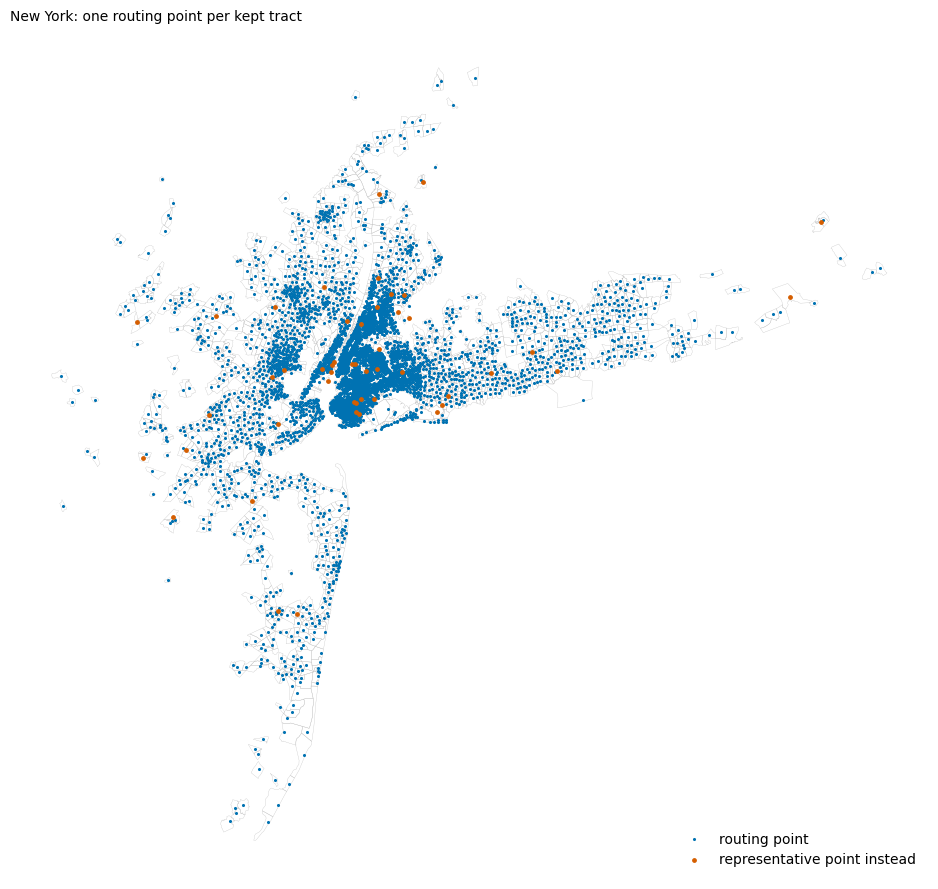

In [7]:
routing_points = gpd.GeoDataFrame({"id": points["tract"]}, geometry=points["point"].to_numpy(), crs="EPSG:4326")
routing_points.to_parquet(RESULTS / f"tract-points-{YEAR}.parquet", index=False)

figure, axis = plt.subplots(figsize=(11, 9))
points.plot(ax=axis, facecolor="none", edgecolor="#bbbbbb", linewidth=0.2)
routing_points.plot(ax=axis, color="#0072B2", markersize=1.5, label="routing point")
points.loc[points["method"] != "weighted mean of block points"].set_geometry("point").plot(ax=axis, color="#D55E00", markersize=6, label="representative point instead")
axis.legend(frameon=False, loc="lower right")
axis.set_aspect(1 / np.cos(np.radians(points["lat"].mean())))
axis.set_title(f"{CITY}: one routing point per kept tract", loc="left", fontsize=10)
axis.set_axis_off()
figure.tight_layout()


## 4. Street network

The cafein street network of the area: walking, cycling and car, from the extract
clipped to the bounding box of the kept tracts, with the United States defaults for
untagged speed limits. Built once and saved in `networks/`; later runs load it.


In [8]:
if not OSM_PBF.exists():
    OSM_PBF.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(OSM_URL, OSM_PBF)
print(OSM_PBF.name, f"{OSM_PBF.stat().st_size / 1e9:.2f} GB")

bounding_box = tuple(tracts.to_crs("EPSG:4326").total_bounds)
started = time.time()
if STREET_ARTIFACT.exists():
    streets = StreetNetwork.load(STREET_ARTIFACT)
    print("loaded", STREET_ARTIFACT)
else:
    streets = StreetNetwork.from_osm(OSM_PBF, modes=("walk", "bicycle", "car"), country=COUNTRY, bounding_box=bounding_box)
    streets.save(STREET_ARTIFACT)
    print("built and saved", STREET_ARTIFACT)
print(f"{time.time() - started:.0f} s; bounding box {np.round(bounding_box, 3)}; vertices {streets.vertex_count:,}, edges {streets.edge_count:,}")


us-northeast-latest.osm.pbf 1.81 GB


loaded ../../../networks/new-york-streets.cafein
6 s; bounding box [-74.981  39.509 -72.146  41.499]; vertices 11,551,871, edges 12,634,812


## 5. Snapping

Routing starts and ends on a street, so each point is moved to one. The rule is the
London one: the nearest point of the street network that lies **inside the tract**, and
at most `SNAP_DISTANCE_M` away; every edge of the network counts as a street, whatever
modes may use it. A tract with no street within that distance inside its own polygon is
left without a routable point. The snapped points, with the tract code as id, are what
the routing uses from here on.


In [9]:
started = time.time()
edges = streets.streets_gdf[["geometry"]].to_crs(METRIC_CRS)
polygons = points[["tract", "geometry"]].to_crs(METRIC_CRS)
centres = gpd.GeoSeries(points["point"], crs="EPSG:4326").to_crs(METRIC_CRS)
print(f"{len(edges):,} edges in {METRIC_CRS}, {time.time() - started:.0f} s")

# Which edges touch which tract (an edge crossing a border appears in both tracts).
edges_in_tracts = gpd.sjoin(edges, polygons, how="inner", predicate="intersects")
print(f"{len(edges_in_tracts):,} edge-tract matches, {time.time() - started:.0f} s")

snapped = []
for (tract, polygon), centre in zip(polygons[["tract", "geometry"]].itertuples(index=False), centres):
    inside = edges_in_tracts.loc[edges_in_tracts["tract"] == tract, "geometry"]
    if len(inside) == 0:
        snapped.append({"tract": tract, "snap_distance_m": np.nan, "snapped": None})
        continue
    # Keep only the parts of the edges that lie inside the tract, then take the closest point.
    streets_inside = inside.intersection(polygon).union_all()
    point_on_street = nearest_points(centre, streets_inside)[1]
    snapped.append({"tract": tract, "snap_distance_m": centre.distance(point_on_street), "snapped": point_on_street})
snapped = pd.DataFrame(snapped)
points = points.drop(columns=[c for c in ["snap_distance_m", "snapped", "within_rule"] if c in points.columns]).merge(snapped, on="tract")
points["within_rule"] = points["snap_distance_m"] <= SNAP_DISTANCE_M
print(f"snapping done in {time.time() - started:.0f} s")

print(f"{len(points):,} tracts; {points['snap_distance_m'].isna().sum()} with no street inside at all; "
      f"{(~points['within_rule']).sum()} left without a point under the {SNAP_DISTANCE_M} m rule")
print("distance from the point to the snapped point (m):")
display(points["snap_distance_m"].describe(percentiles=[0.5, 0.9, 0.99]).round(0).to_frame().T)
print("tracts left without a routable point:")
points.loc[~points["within_rule"], ["tract", "NAMELSADCO", "land_km2", "workers_home", "workers_work", "snap_distance_m"]].round(0)


12,634,812 edges in EPSG:32618, 126 s


5,958,223 edge-tract matches, 135 s


snapping done in 858 s
4,589 tracts; 0 with no street inside at all; 1 left without a point under the 1000 m rule
distance from the point to the snapped point (m):


,count,mean,std,min,50%,90%,99%,max
snap_distance_m,4589.0,18.0,33.0,0.0,12.0,37.0,107.0,1171.0


tracts left without a routable point:


,tract,NAMELSADCO,land_km2,workers_home,workers_work,snap_distance_m
4180,34029980000,Ocean County,10.0,29,0.0,1171.0


4,588 routing points saved; they carry 100.00% of the resident workers


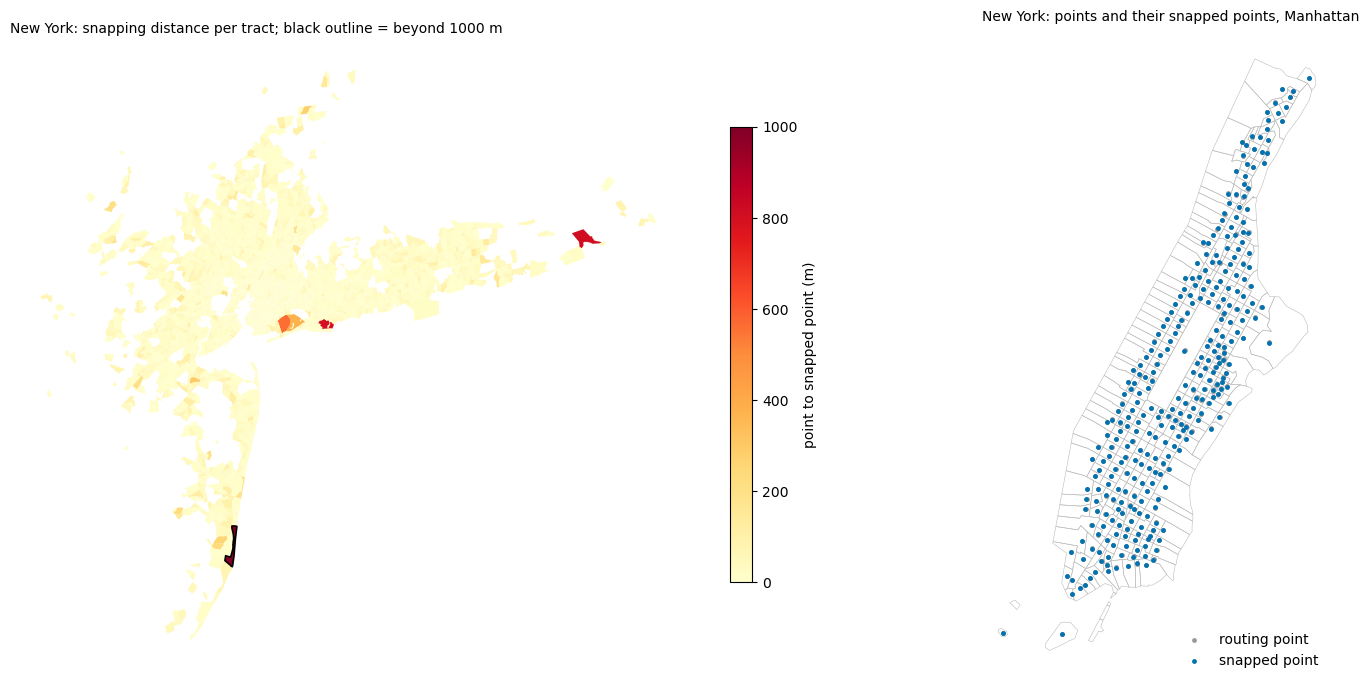

In [10]:
routing_points = gpd.GeoDataFrame(
    {"id": points.loc[points["within_rule"], "tract"].to_numpy()},
    geometry=points.loc[points["within_rule"], "snapped"].to_numpy(), crs=METRIC_CRS,
).to_crs("EPSG:4326")
routing_points.to_parquet(RESULTS / f"tract-points-snapped-{YEAR}.parquet", index=False)
print(f"{len(routing_points):,} routing points saved; they carry {points.loc[points['within_rule'], 'workers_home'].sum() / points['workers_home'].sum():.2%} of the resident workers")

figure, axes = plt.subplots(ncols=2, figsize=(16, 7))
points.plot(column="snap_distance_m", ax=axes[0], cmap="YlOrRd", vmin=0, vmax=SNAP_DISTANCE_M, edgecolor="none",
            legend=True, legend_kwds={"shrink": 0.7, "label": "point to snapped point (m)"},
            missing_kwds={"color": "#444444", "label": "no street inside"})
points.loc[~points["within_rule"]].plot(ax=axes[0], facecolor="none", edgecolor="black", linewidth=1.2)
axes[0].set_title(f"{CITY}: snapping distance per tract; black outline = beyond {SNAP_DISTANCE_M} m", loc="left", fontsize=10)

manhattan = points.loc[points["NAMELSADCO"] == "New York County"]
manhattan.plot(ax=axes[1], facecolor="none", edgecolor="#bbbbbb", linewidth=0.4)
gpd.GeoSeries(manhattan["point"], crs="EPSG:4326").plot(ax=axes[1], color="#999999", markersize=6, label="routing point")
gpd.GeoSeries(manhattan["snapped"], crs=METRIC_CRS).to_crs("EPSG:4326").plot(ax=axes[1], color="#0072B2", markersize=6, label="snapped point")
axes[1].legend(frameon=False, loc="lower right")
axes[1].set_title(f"{CITY}: points and their snapped points, Manhattan", loc="left", fontsize=10)
for axis in axes:
    axis.set_aspect(1 / np.cos(np.radians(points["lat"].mean())))
    axis.set_axis_off()
figure.tight_layout()


## 6. Street modes

Car, bicycle and e-bike travel times between every pair of routing points, with cafein's street
router on the saved network, as in London: one `TravelTimeMatrix` per query streamed to a
folder on scratch and reused on later runs when complete. Car is computed twice, free-flow
and with intersection delays at the rush profile; bicycle and e-bike once each. The e-bike rides the same streets as the bicycle at 17.4 km/h on the flat against the
bicycle's 15.3, the mean trip speeds of pedelecs and conventional bicycles in Schleinitz et
al. (2017) and cafein's defaults, set as in Helsinki; there is no elevation model here, so
neither mode is slowed by slopes. Times are kept in seconds on
disk and read back in minutes. The tract flows of step 2 are then joined to the matrices, so
each pair of tracts carries its workers and its times. cafein stops a street route at 120
minutes, so a ride longer than that counts as not reached.


In [11]:
def matrix_complete(path):
    # True when a streamed matrix folder has every shard completed.
    manifest = Path(path) / "manifest.json"
    if not manifest.is_file():
        return False
    shards = json.loads(manifest.read_text())["shards"]
    return bool(shards) and all(shard["completed"] for shard in shards)


for mode in STREET_MODES:
    output = MATRICES / STREET_QUERIES[mode]["folder"]
    if matrix_complete(output):
        print(f"{mode:8} complete -> {output}")
        continue
    started = time.time()
    TravelTimeMatrix.to_parquet(streets, routing_points, routing_points, output=output, output_time_units="seconds",
                                resume=output.exists(), **STREET_QUERIES[mode]["query"])
    print(f"{mode:8} {time.time() - started:6.0f} s -> {output}")


car_freeflow complete -> /scratch/project_2010423/carbon-advantage/commuting/new-york/matrices/car
car      complete -> /scratch/project_2010423/carbon-advantage/commuting/new-york/matrices/car-rush
bicycle  complete -> /scratch/project_2010423/carbon-advantage/commuting/new-york/matrices/bicycle
e_bike   complete -> /scratch/project_2010423/carbon-advantage/commuting/new-york/matrices/e_bike


In [12]:
od_times = od.loc[od["from_id"].isin(routing_points["id"]) & od["to_id"].isin(routing_points["id"])].copy()
coordinates = routing_points.set_index("id").geometry
home_lon, home_lat = coordinates.x.loc[od_times["from_id"]].to_numpy(), coordinates.y.loc[od_times["from_id"]].to_numpy()
work_lon, work_lat = coordinates.x.loc[od_times["to_id"]].to_numpy(), coordinates.y.loc[od_times["to_id"]].to_numpy()
od_times["straight_km"] = np.hypot((work_lon - home_lon) * np.cos(np.radians(home_lat)) * 111.32, (work_lat - home_lat) * 110.57)

for mode in STREET_MODES:
    matrix = read_shards(MATRICES / STREET_QUERIES[mode]["folder"])[["from_id", "to_id", "travel_time"]].rename(columns={"travel_time": f"{mode}_min"})
    matrix[f"{mode}_min"] = matrix[f"{mode}_min"] / 60
    od_times = od_times.merge(matrix, on=["from_id", "to_id"], how="left")
od_times.to_parquet(MATRICES / f"tract-od-times-{YEAR}.parquet", index=False)
print(f"{len(od_times):,} tract pairs with a flow between routing points, {od_times['workers'].sum():,} workers")
od_times.head()


2,408,240 tract pairs with a flow between routing points, 6,708,932 workers


,from_id,to_id,workers,straight_km,car_freeflow_min,car_min,bicycle_min,e_bike_min
0,34003001001,34003001001,55,0.000000,0.000000,0.000000,0.000000,0.000000
1,34003001001,34003001002,44,1.280945,2.600000,5.866667,8.783333,7.850000
2,34003001001,34003002200,9,15.082558,19.733333,51.916667,72.816667,64.150000
3,34003001001,34003003200,1,16.480021,17.683333,52.300000,79.650000,70.166667
4,34003001001,34003006201,1,26.388379,23.783333,57.500000,120.000000,105.666667


In [13]:
def weighted_percentiles(values, weights, percentiles):
    order = np.argsort(values)
    cumulative = np.cumsum(weights[order]) / weights.sum()
    return [values[order][np.searchsorted(cumulative, p / 100)] for p in percentiles]


def weighted_median(values, weights):
    order = np.argsort(values)
    cumulative = np.cumsum(weights[order]) / weights.sum()
    return values[order][np.searchsorted(cumulative, 0.5)]


summary = {}
for mode in STREET_MODES:
    reached = od_times[f"{mode}_min"].notna()
    minutes = od_times.loc[reached, f"{mode}_min"].to_numpy()
    weights = od_times.loc[reached, "workers"].to_numpy()
    straight = od_times.loc[reached, "straight_km"].to_numpy()
    summary[mode] = {
        "share of workers reached": weights.sum() / od_times["workers"].sum(),
        "mean minutes, worker-weighted": np.average(minutes, weights=weights),
        "median minutes, worker-weighted": weighted_median(minutes, weights),
        "p90 minutes, worker-weighted": weighted_percentiles(minutes, weights, [90])[0],
                # Straight-line distance covered per hour, over the pairs between different tracts.
        "straight-line km per hour, between tracts": straight[minutes > 0].dot(weights[minutes > 0]) / (minutes[minutes > 0] / 60).dot(weights[minutes > 0]),
    }
print("commutes between the kept tracts, by mode:")
pd.DataFrame(summary).round(2)


commutes between the kept tracts, by mode:


,car_freeflow,car,bicycle,e_bike
share of workers reached,1.00,0.99,0.75,0.79
"mean minutes, worker-weighted",17.90,35.11,47.03,44.96
"median minutes, worker-weighted",14.18,31.02,42.00,39.10
"p90 minutes, worker-weighted",36.60,65.47,95.28,93.50
"straight-line km per hour, between tracts",55.49,27.36,12.03,13.51


median minutes per home tract, across tracts:


,count,mean,std,min,25%,50%,75%,max
car_freeflow_median_min,4585.0,16.3,6.6,0.0,12.6,15.2,18.6,74.5
car_median_min,4585.0,34.2,11.6,0.0,27.0,32.5,40.0,93.6
bicycle_median_min,4584.0,46.6,15.8,0.0,37.5,47.2,56.3,111.9
e_bike_median_min,4584.0,44.0,15.9,0.0,34.8,44.1,52.7,110.9


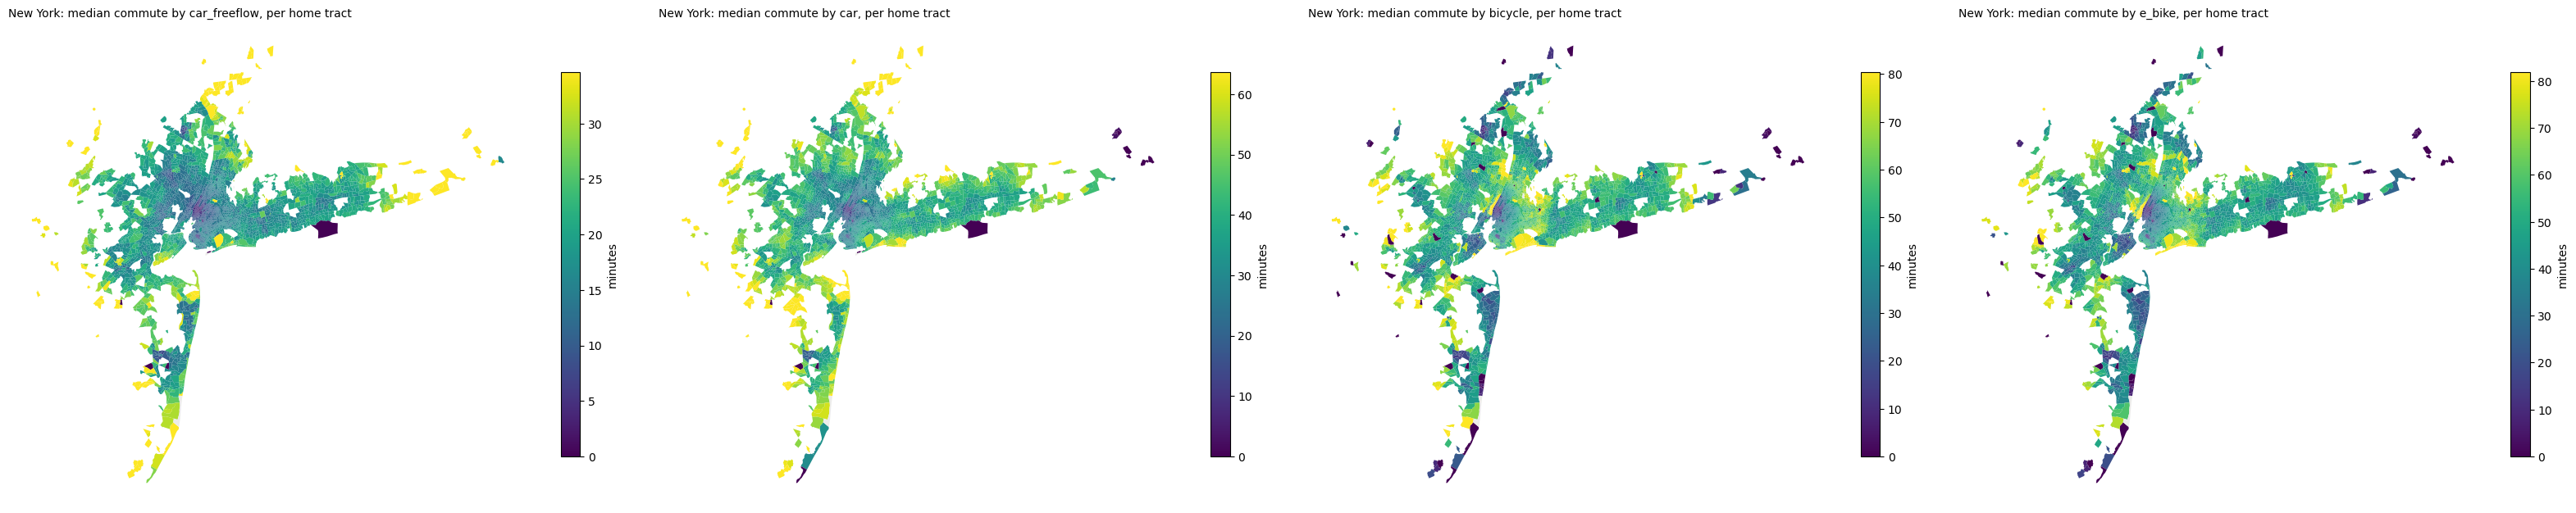

In [14]:
per_tract = pd.DataFrame({"residents": od_times.groupby("from_id")["workers"].sum()})
for mode in STREET_MODES:
    column = f"{mode}_min"
    reached = od_times.loc[od_times[column].notna()]
    per_tract[f"{mode}_median_min"] = reached.groupby("from_id").apply(lambda rows: weighted_median(rows[column].to_numpy(), rows["workers"].to_numpy()), include_groups=False)
per_tract = per_tract.rename_axis("tract").reset_index()
per_tract.to_parquet(MATRICES / f"median-minutes-by-home-tract-{YEAR}.parquet", index=False)

mapped = tracts[["tract", "geometry"]].merge(per_tract, on="tract", how="left")
figure, axes = plt.subplots(ncols=len(STREET_MODES), figsize=(8 * len(STREET_MODES), 7))
for axis, mode in zip(axes, STREET_MODES):
    column = f"{mode}_median_min"
    mapped.plot(column=column, ax=axis, cmap="viridis", vmin=0, vmax=np.nanpercentile(mapped[column], 98), edgecolor="none",
                legend=True, legend_kwds={"shrink": 0.7, "label": "minutes"}, missing_kwds={"color": "#ececea"})
    axis.set_title(f"{CITY}: median commute by {mode}, per home tract", loc="left", fontsize=10)
    axis.set_aspect(1 / np.cos(np.radians(points["lat"].mean())))
    axis.set_axis_off()
figure.tight_layout()
print("median minutes per home tract, across tracts:")
per_tract[[f"{mode}_median_min" for mode in STREET_MODES]].describe(percentiles=[0.25, 0.5, 0.75]).round(1).T


## 7. Timetables

The transit feeds of the area, fetched through transitio for the departure date with the
polygon of the kept tracts as the area of interest: transitio looks up the feeds its index
records for the places covering that polygon, downloads them, validates them and repairs
what it can, and skips the ones with no service on the date. The PATH train between New
Jersey and Manhattan is a protected feed transitio cannot fetch; the Port Authority's open
upload to the National RTAP file manager is downloaded separately and added to the list.
The table lists what is inside each feed: agencies, routes by GTFS route type (0 tram,
1 metro, 2 rail, 3 bus, 4 ferry), stops, trips and the calendar span.


In [15]:
started = time.time()
area = tracts.to_crs("EPSG:4326").union_all()
fetched = transitio.fetch(aoi=area, when=pd.Timestamp(DEPARTURE).date(), osm=False, directory=GTFS_DIR)
print(f"transitio fetch done in {time.time() - started:.0f} s")
if not PATH_GTFS.exists():
    urllib.request.urlretrieve(PATH_GTFS_URL, PATH_GTFS)
GTFS_FILES = [Path(str(feed)) for feed in fetched.feeds] + [PATH_GTFS]
print(f"{len(GTFS_FILES)} feeds delivered, {sum(path.stat().st_size for path in GTFS_FILES) / 1e6:.0f} MB")
print("skipped:", fetched.skipped)
for report in fetched.reports:
    print("report:", str(report)[:400])


Fetching 78 feeds for the area


[1/78] f-9-amtrak~amtrakcalifornia~amtrakcharteredvehicle: skipped (not considered: serves the place at the national and international tiers; fetch takes it when named in feeds=)


[2/78] f-trailways~nyp~ny: skipped (not considered: serves the place at the national tier; fetch takes it when named in feeds=)


[3/78] f-trailways~adp~ny: skipped (not considered: serves the place at the national tier; fetch takes it when named in feeds=)


[4/78] f-amtrakvermonter~vt~us: skipped (not considered: serves the place at the national tier; fetch takes it when named in feeds=)


[5/78] f-concord~coach~lines: skipped (not considered: serves the place at the national tier; fetch takes it when named in feeds=)


... (79 outputs left out)

Comparing trips across 52 feeds


/tmp/marinflo/3371581/ipykernel_768970/2465570415.py:3: UserWarning: trips left out as near repeats took departures at stops the trips they repeat do not serve: f-dr5r-nyctsubway: 558 at 2 stops (711S, 713S); f-adirondack~trailways~adt: 2 at 1 stops (1467); duplicate_trips="exact" keeps near repeats
  fetched = transitio.fetch(aoi=area, when=pd.Timestamp(DEPARTURE).date(), osm=False, directory=GTFS_DIR)
[75/78] f-adirondack~trailways~adt: left out (every trip on 2026-11-10 repeats a trip of f-mdb-tld-5781)


Done in 1 min 24 s: 51 feeds delivered, 27 skipped, 4.3 MB downloaded


transitio fetch done in 85 s
52 feeds delivered, 205 MB
skipped: [('f-mdb-ntd-20190', 'service ended 2024-09-02; unchanged since indexed'), ('f-libertylandingferry~ny~us', 'service ended 2020-08-01; unchanged since indexed'), ('f-governorsislandferry~ny~us', 'service ended 2019-10-31; unchanged since indexed'), ('f-mdb-519', 'service ended 2026-10-31; unchanged since indexed'), ('f-mdb-ntd-20220', 'service ended 2022-12-31; unchanged since indexed'), ('f-mdb-522', 'service ended 2021-12-31; unchanged since indexed'), ('f-dr5r-path~nj~us', 'protected feed: the index has no access details for it; Port Authority Trans-Hudson needs credentials; the index has no access details for it yet.'), ('f-mdb-517', 'service ended 2026-06-01; unchanged since indexed'), ('f-princeton~tigertransit', 'no trip stops in the area'), ('f-rockland~ny~us', 'service ended 2026-10-31'), ('f-mdb-511', 'same content as f-dr5r-mtanewyorkcitytransit'), ('f-mdb-2353', 'service ended 2025-08-31'), ('f-academy~express~

**Units of the shape distances.** cafein 0.31 decides per trip whether a feed's `shape_dist_traveled` is in metres or kilometres and takes feet for metres, which makes every ridden distance and the grams computed from it 3.28 times too large for operators that publish feet (CTA; Sound Transit, King County Metro and Intercity Transit). The script `jobs/fix-gtfs-shape-dist-units.py` decides the unit once per feed from its shapes and rewrites feet feeds in metres, in place; it runs here after every fetch, before the network is built, and leaves metre feeds alone.

In [ ]:
import subprocess
import sys

fix = subprocess.run([sys.executable, "../../jobs/fix-gtfs-shape-dist-units.py", str(GTFS_DIR), "--apply"], capture_output=True, text=True)
print(fix.stdout + fix.stderr)

In [16]:
ROUTE_TYPE_NAMES = {0: "tram", 1: "metro", 2: "rail", 3: "bus", 4: "ferry", 5: "cable tram", 6: "aerial", 7: "funicular", 11: "trolleybus", 12: "monorail"}


def gtfs_summary(path):
    # Counts and dates of one GTFS zip, without unpacking it to disk.
    with zipfile.ZipFile(path) as archive:
        names = set(archive.namelist())
        agency = pd.read_csv(archive.open("agency.txt"))
        routes = pd.read_csv(archive.open("routes.txt"))
        stops = pd.read_csv(archive.open("stops.txt"), usecols=["stop_id"])
        trips = pd.read_csv(archive.open("trips.txt"), usecols=["trip_id"])
        dates = []
        if "calendar.txt" in names:
            calendar = pd.read_csv(archive.open("calendar.txt"), dtype=str)
            dates += [calendar["start_date"].min(), calendar["end_date"].max()]
        if "calendar_dates.txt" in names:
            exceptions = pd.read_csv(archive.open("calendar_dates.txt"), dtype=str)
            dates += [exceptions["date"].min(), exceptions["date"].max()]
    by_type = routes["route_type"].map(lambda t: ROUTE_TYPE_NAMES.get(int(t), f"type {t}")).value_counts()
    return {"file": Path(path).name, "agencies": len(agency), "routes": len(routes), "stops": len(stops), "trips": len(trips),
            "first_date": min(dates) if dates else None, "last_date": max(dates) if dates else None, **{f"routes_{k}": v for k, v in by_type.items()}}


feeds = pd.DataFrame([gtfs_summary(path) for path in GTFS_FILES]).set_index("file").sort_values("trips", ascending=False)
feeds[[c for c in feeds.columns if c.startswith("routes_")]] = feeds[[c for c in feeds.columns if c.startswith("routes_")]].fillna(0).astype(int)
print(f"{len(feeds)} feeds, {feeds['trips'].sum():,} trips, {feeds['stops'].sum():,} stops")
pd.set_option("display.max_rows", 100)
feeds


52 feeds, 423,771 trips, 38,618 stops


,agencies,routes,stops,trips,first_date,last_date,routes_ferry,routes_bus,routes_tram,routes_metro,routes_rail
file,,,,,,,,,,,
f-dr5r-mtanewyorkcitytransit.zip,1,29,1487,83805,20261101,20270515,0,0,0,28,1
f-dr5r-mtanyctbusbrooklyn.zip,1,68,4575,58357,20261008,20270102,0,68,0,0,0
f-dr5r-mtabc.zip,1,92,2758,45424,20261009,20270102,0,92,0,0,0
f-dr72-mtanyctbusbronx.zip,1,46,1890,41156,20261008,20270102,0,46,0,0,0
f-dr5r-mtanyctbusmanhattan.zip,1,41,1823,37872,20261008,20270102,0,41,0,0,0
f-dr5x-mtanyctbusqueens.zip,1,40,1422,31199,20261008,20270102,0,40,0,0,0
f-dr7-mtanyc~metro~north.zip,1,5,106,29375,20261101,20270522,0,0,0,0,5
f-dr5-nj~transit~bus.zip,1,203,11729,27681,20261020,20270417,0,203,0,0,0
f-dr5r-mtanyctbusstatenisland.zip,1,58,1965,16524,20261012,20270102,0,58,0,0,0


## 8. Transit

One `TransportNetwork` from the 52 feeds and the OSM extract, with the street modes added
so the same network could serve them too, clipped to the bounding box of the kept tracts.
Built once and saved on scratch; later runs load it. Then one `TravelTimeMatrix` for
transit between all routing points at the departure, streamed to scratch like the street
matrices, with the walk to the first stop and from the last stop capped at 30 minutes, as in 05.9 and 05.10, and cafein's defaults for transfers. The transit times join
the table of step 6, and the summary and the maps are repeated for all modes.


In [17]:
started = time.time()
if TRANSIT_ARTIFACT.exists():
    transit_network = TransportNetwork.load(TRANSIT_ARTIFACT)
    print("loaded", TRANSIT_ARTIFACT)
else:
    transit_network = TransportNetwork.from_gtfs(GTFS_FILES, osm_pbf=OSM_PBF, street_modes=("walk", "bicycle", "car"),
                                                 country=COUNTRY, bounding_box=bounding_box)
    transit_network.save(TRANSIT_ARTIFACT)
    print("built and saved", TRANSIT_ARTIFACT)
print(f"{time.time() - started:.0f} s; {transit_network.stop_count:,} stops, {transit_network.trip_count:,} trips")


loading the network:   0%|          | 0/2 [00:02<?, ?it/s]

loaded /scratch/project_2010423/carbon-advantage/commuting/new-york/new-york-transit.cafein
15 s; 38,618 stops, 424,160 trips


In [18]:
output = MATRICES / f"transit-walk{ACCESS_EGRESS_WALK_MIN}"
if matrix_complete(output):
    print(f"transit  complete -> {output}")
else:
    started = time.time()
    TravelTimeMatrix.to_parquet(transit_network, routing_points, routing_points, output=output, departure=DEPARTURE, max_walking_time=ACCESS_EGRESS_WALK_MIN,
                                output_time_units="seconds", resume=output.exists())
    print(f"transit  {time.time() - started:6.0f} s -> {output}")

matrix = read_shards(output)[["from_id", "to_id", "travel_time"]].rename(columns={"travel_time": "transit_min"})
matrix["transit_min"] = matrix["transit_min"] / 60
od_times = od_times.drop(columns=[c for c in ["transit_min"] if c in od_times.columns]).merge(matrix, on=["from_id", "to_id"], how="left")
od_times.to_parquet(MATRICES / f"tract-od-times-{YEAR}.parquet", index=False)

summary = {}
for mode in MODES:
    reached = od_times[f"{mode}_min"].notna()
    minutes = od_times.loc[reached, f"{mode}_min"].to_numpy()
    weights = od_times.loc[reached, "workers"].to_numpy()
    straight = od_times.loc[reached, "straight_km"].to_numpy()
    summary[mode] = {
        "share of workers reached": weights.sum() / od_times["workers"].sum(),
        "mean minutes, worker-weighted": np.average(minutes, weights=weights),
        "median minutes, worker-weighted": weighted_median(minutes, weights),
        "p90 minutes, worker-weighted": weighted_percentiles(minutes, weights, [90])[0],
        "straight-line km per hour, between tracts": straight[minutes > 0].dot(weights[minutes > 0]) / (minutes[minutes > 0] / 60).dot(weights[minutes > 0]),
    }
print("commutes between the kept tracts, by mode:")
pd.DataFrame(summary).round(2)


travel_time_matrix:  50%|#####     | 250/500 [00:02<00:02, 124.73it/s]

travel_time_matrix:  50%|#####     | 250/500 [00:02<00:02, 124.75it/s]

travel_time_matrix:  50%|#####     | 250/500 [00:02<00:02, 124.72it/s]

travel_time_matrix:  50%|#####     | 250/500 [00:02<00:02, 124.72it/s]

travel_time_matrix:  50%|#####     | 250/500 [00:02<00:02, 124.74it/s]

travel_time_matrix:  55%|#####5    | 275/500 [00:02<00:01, 137.21it/s]

... (2 outputs left out)

travel_time_matrix:  65%|######5   | 325/500 [00:02<00:01, 162.17it/s]

transit      60 s -> /scratch/project_2010423/carbon-advantage/commuting/new-york/matrices/transit-walk30


commutes between the kept tracts, by mode:


,car_freeflow,car,bicycle,e_bike,transit
share of workers reached,1.00,0.99,0.75,0.79,0.91
"mean minutes, worker-weighted",17.90,35.11,47.03,44.96,84.29
"median minutes, worker-weighted",14.18,31.02,42.00,39.10,65.87
"p90 minutes, worker-weighted",36.60,65.47,95.28,93.50,155.40
"straight-line km per hour, between tracts",55.49,27.36,12.03,13.51,11.00


median minutes per home tract, across tracts:


,count,mean,std,min,25%,50%,75%,max
car_freeflow_median_min,4585.0,16.3,6.6,0.0,12.6,15.2,18.6,74.5
car_median_min,4585.0,34.2,11.6,0.0,27.0,32.5,40.0,93.6
bicycle_median_min,4584.0,46.6,15.8,0.0,37.5,47.2,56.3,111.9
e_bike_median_min,4584.0,44.0,15.9,0.0,34.8,44.1,52.7,110.9
transit_median_min,4578.0,76.6,67.5,0.0,47.7,64.4,91.2,735.9


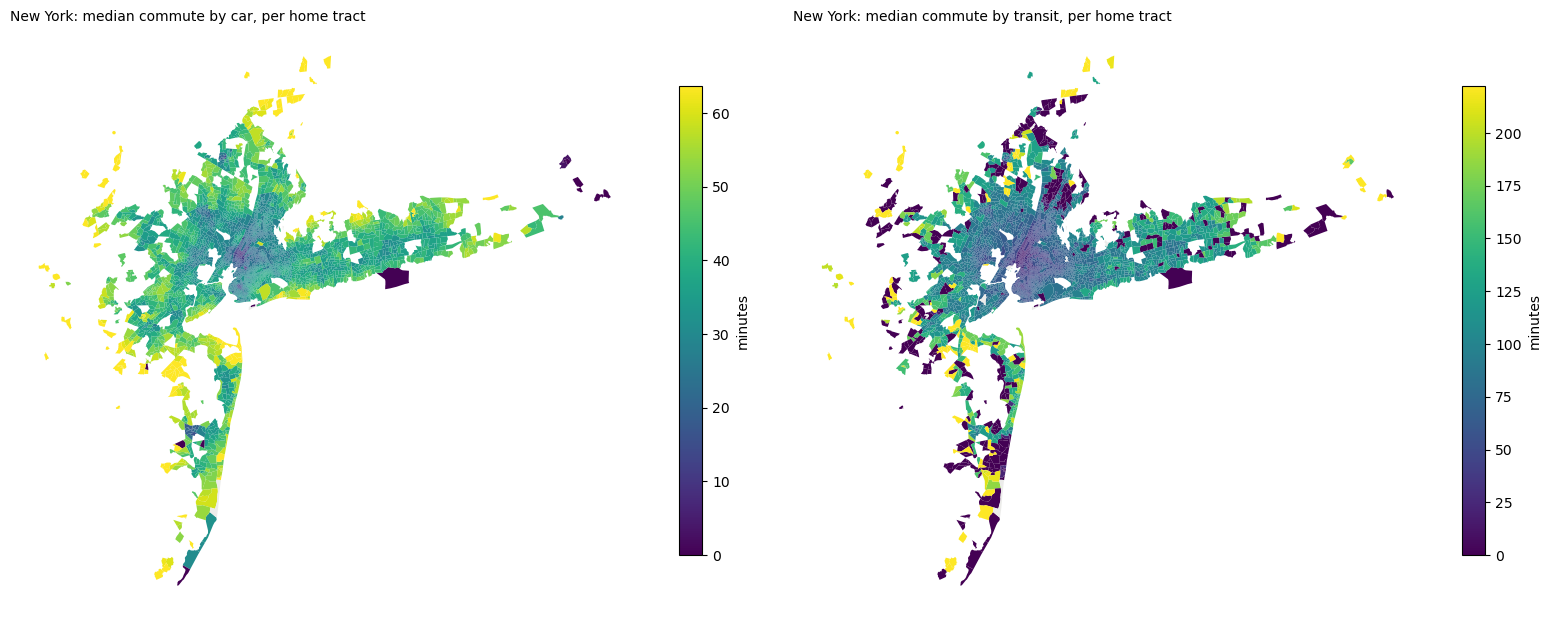

In [19]:
per_tract = pd.DataFrame({"residents": od_times.groupby("from_id")["workers"].sum()})
for mode in MODES:
    column = f"{mode}_min"
    reached = od_times.loc[od_times[column].notna()]
    per_tract[f"{mode}_median_min"] = reached.groupby("from_id").apply(lambda rows: weighted_median(rows[column].to_numpy(), rows["workers"].to_numpy()), include_groups=False)
per_tract = per_tract.rename_axis("tract").reset_index()
per_tract.to_parquet(MATRICES / f"median-minutes-by-home-tract-{YEAR}.parquet", index=False)

mapped = tracts[["tract", "geometry"]].merge(per_tract, on="tract", how="left")
figure, axes = plt.subplots(ncols=2, figsize=(16, 7))
for axis, mode in zip(axes, ["car", "transit"]):
    column = f"{mode}_median_min"
    mapped.plot(column=column, ax=axis, cmap="viridis", vmin=0, vmax=np.nanpercentile(mapped[column], 98), edgecolor="none",
                legend=True, legend_kwds={"shrink": 0.7, "label": "minutes"}, missing_kwds={"color": "#ececea"})
    axis.set_title(f"{CITY}: median commute by {mode}, per home tract", loc="left", fontsize=10)
    axis.set_aspect(1 / np.cos(np.radians(points["lat"].mean())))
    axis.set_axis_off()
figure.tight_layout()
print("median minutes per home tract, across tracts:")
per_tract[[f"{mode}_median_min" for mode in MODES]].describe(percentiles=[0.25, 0.5, 0.75]).round(1).T
